John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

# Candidate-level match model using the 60 s window features

This notebook combines:

* **the structure of notebook 03**: one row per (event, candidate song type), a binary `match` target, a grouped train/test split and grouped CV by `event_id`, tuning on top-1 candidate-selection accuracy, and prediction by picking the candidate with the highest P(match) in each event;
* **the input features of notebook 21**: the neighbours' song counts in the last 60 s (`*window*` columns), the focal male's last two song types, and the time since his last two songs.

**Predictors on each candidate row**

| Group | Columns | Notes |
|---|---|---|
| Window features | every `*window*` column except `target`, `others` and `candidate_*` | Same selection rule as notebook 21. Identical for every candidate in an event. |
| Candidate identity | `candidate_ust` | Needed so the forest can learn song-specific responses to the window features. Without it, event-level constants cannot separate candidates. |
| Own song history (types) | `focal_last_1_ust`, `focal_last_2_ust` | Raw song types as factors, as in notebook 21. |
| Own song history (timing) | `focal_time_since_last_1`, `focal_time_since_last_2` | Seconds since the focal male's last two songs. |

**Deliberately not used** (they are notebook 03's candidate-aligned features): `candidate_n_ust_window` and `candidate_matches_M*_k_last_UST`.

Import Packages

In [1]:
# data.table is loaded first so that dplyr's first()/last()/between() take precedence
library(data.table)
library(tidyverse)
library(tidymodels)
library(vip)
library(ranger)
library(furrr)
set.seed(42)

Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'tidyverse' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'tibble' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'readr' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'lubridate' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::between()     masks data.ta

Settings

In [2]:
MODEL_NAME <- "candidate_match_distance_weighted_window60"

CANDIDATE_DIR <- "data/by_id"
RESULTS_DIR   <- "data/2026_results"

# Own-song history lags. Notebook 21 uses lags 1 and 2 (its 3rd lag is commented out).
OWN_LAGS <- 1:2

# In notebook 21 the n_ust_*_window counts reach the model as factors
# (as.factor(across(contains("UST"))) is case-insensitive, so it also catches "n_ust_*_window").
# TRUE reproduces that; FALSE treats the counts as numeric.
WINDOW_AS_FACTOR <- TRUE

# Distance-weighted neighbour features from notebook 02 (columns ending in _wtd, plus the unweighted
# n_songs_ / n_singers_ counterparts). They are continuous, so they are kept numeric.

ADD_DIST_WEIGHTED <- TRUE

# Notebook 21 used drop_na(). In candidate data a missing feature belongs to the whole event,
# so TRUE drops every event that has an NA in any predictor (this keeps exactly one match per event).
# FALSE keeps those events and imputes in the recipe (median for numeric, "unknown" for factors).
DROP_NA_EVENTS <- TRUE

Load candidate-level data (the window columns are already in the candidate files)

In [3]:
candidate_files <- list.files(CANDIDATE_DIR, pattern = "_candidate_classification\\.csv$", full.names = TRUE)
if (length(candidate_files) == 0) stop("No *_candidate_classification.csv files found in ", CANDIDATE_DIR)

# To test only a single classifier, uncomment the next line:
# candidate_files <- candidate_files[1]

# Window columns, selected the way notebook 21 does it:
# contains("window"), minus "target" and "others" -- and minus the candidate-specific candidate_* columns.
select_window_cols <- function(col_names) {
    has_window <- str_detect(col_names, regex("window", ignore_case = TRUE))
    excluded   <- str_detect(col_names, regex("target|others", ignore_case = TRUE)) |
                  str_starts(col_names, "candidate_")
    col_names[has_window & !excluded]
}

# Distance-weighted features written by notebook 02. Their names contain no "window", so
# select_window_cols() never matches them and WINDOW_AS_FACTOR can't turn them into factors.
select_weighted_cols <- function(col_names) {
    col_names[str_detect(col_names, "_wtd$|^n_(songs|singers)_last[0-9]+s$")]
}

ID_COLS <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")

build_male_data <- function(song_data, id_value, number_value, source_name) {
    male_prefix   <- paste0("M", number_value)
    own_type_cols <- paste0(male_prefix, "_", OWN_LAGS, "_last_UST")
    own_time_cols <- paste0("time_since_", male_prefix, "_", OWN_LAGS, "_last_song")
    window_cols   <- select_window_cols(names(song_data))
    weighted_cols <- if (ADD_DIST_WEIGHTED) select_weighted_cols(names(song_data)) else character(0)

    required_columns <- c("event_id", "candidate_ust", "match", own_type_cols, own_time_cols)
    missing_columns  <- setdiff(required_columns, names(song_data))
    if (length(missing_columns) > 0) {
        stop(sprintf("Missing required columns in %s for %s: %s",
                     source_name, male_prefix, paste(missing_columns, collapse = ", ")))
    }
    if (length(window_cols) == 0) {
        stop(sprintf("No window columns found in %s. Check select_window_cols().", source_name))
    }
    if (ADD_DIST_WEIGHTED && length(weighted_cols) == 0) {
        stop(sprintf("No distance-weighted columns found in %s. Re-run notebook 02.", source_name))
    }

    # Standardised names for the own-history features
    own_type_new <- paste0("focal_last_", OWN_LAGS, "_ust")
    own_time_new <- paste0("focal_time_since_last_", OWN_LAGS)

    male_data <- song_data %>%
        filter(as.character(male_number) == number_value) %>%
        select(event_id, candidate_ust, match, all_of(window_cols), all_of(weighted_cols),
               all_of(setNames(own_type_cols, own_type_new)),
               all_of(setNames(own_time_cols, own_time_new))) %>%
        mutate(
            focal_male    = paste0(id_value, "_", male_prefix),
            focal_id      = id_value,
            male_number   = number_value,
            candidate_ust = as.factor(as.character(candidate_ust)),
            match_class   = factor(if_else(match == 1, "match", "no_match"), levels = c("no_match", "match")),
            across(all_of(own_type_new), ~ as.factor(as.character(.x)))
        ) %>%
        select(-match) %>%
        relocate(focal_male, focal_id, male_number, event_id, candidate_ust, match_class)

    if (WINDOW_AS_FACTOR) {
        male_data <- male_data %>% mutate(across(all_of(window_cols), as.factor))
    }

    predictor_cols  <- setdiff(names(male_data), ID_COLS)
    n_events_before <- n_distinct(male_data$event_id)

    if (DROP_NA_EVENTS) {
        na_events <- male_data %>%
            filter(if_any(all_of(predictor_cols), is.na)) %>%
            distinct(event_id)
        male_data <- male_data %>% anti_join(na_events, by = "event_id")
    }

    event_checks <- male_data %>%
        group_by(event_id) %>%
        summarise(n_candidates = n(), n_matches = sum(match_class == "match"), .groups = "drop")
    if (nrow(event_checks) == 0 || any(event_checks$n_candidates < 2) || any(event_checks$n_matches != 1)) {
        stop(sprintf("Invalid candidate events for %s_%s in %s", id_value, male_prefix, source_name))
    }

    attr(male_data, "window_cols")         <- window_cols
    attr(male_data, "predictor_cols")      <- predictor_cols
    attr(male_data, "n_events_dropped_na") <- n_events_before - n_distinct(male_data$event_id)
    male_data
}

model_data_by_male <- list_flatten(map(candidate_files, function(candidate_file) {
    song_data     <- read_csv(candidate_file, show_col_types = FALSE)
    focal_ids     <- song_data %>% distinct(ID) %>% pull(ID)
    focal_numbers <- unique(as.character(song_data$male_number))
    focal_numbers <- focal_numbers[!is.na(focal_numbers)]
    if (length(focal_ids) != 1 || length(focal_numbers) == 0) {
        stop(sprintf("Expected one focal ID and at least one male_number in %s", candidate_file))
    }
    map(focal_numbers, function(focal_number) {
        build_male_data(song_data, focal_ids, focal_number, source_name = candidate_file)
    })
}))
names(model_data_by_male) <- map_chr(model_data_by_male, ~ unique(.x$focal_male))

In [4]:
# Overview of the candidate data actually used for modelling
map_dfr(model_data_by_male, ~ tibble(
    focal_male          = first(.x$focal_male),
    n_events            = n_distinct(.x$event_id),
    n_events_dropped_na = attr(.x, "n_events_dropped_na"),
    n_candidate_rows    = nrow(.x),
    n_song_types        = n_distinct(.x$candidate_ust),
    n_window_cols       = length(attr(.x, "window_cols")),
    n_weighted_cols     = length(attr(.x, "weighted_cols")),
    n_predictors        = length(attr(.x, "predictor_cols"))
))

focal_male,n_events,n_events_dropped_na,n_candidate_rows,n_song_types,n_window_cols,n_weighted_cols,n_predictors
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
DgTbO_M5,1157,10,32396,28,101,0,194
DgTbO_M6,989,10,27692,28,101,0,194
KLgK_M5,508,8,9652,19,59,0,125
KRDg_M2,1011,10,26286,26,59,0,146
LbOW_M1,689,10,12402,18,65,0,128
RbDgY_M2,650,6,13650,21,65,0,137
RRO_M6,525,10,9975,19,65,0,131
TbTbLg_M4,724,10,13756,19,65,0,131
TbWY_M1,594,10,10098,17,59,0,119


In [5]:
# Sanity check: which columns were picked up as window features and as predictors (first male)?
first_male <- model_data_by_male[[1]]
cat("Window columns for", first(first_male$focal_male), ":\n")
print(attr(first_male, "window_cols"))
cat("\nAll predictors:\n")
print(attr(first_male, "predictor_cols"))
glimpse(first_male %>% select(all_of(c("event_id", "candidate_ust", "match_class", head(attr(first_male, "predictor_cols"), 4)))))

Window columns for DgTbO_M5 :
  [1] "n_ust_1_window"   "n_ust_3_window"   "n_ust_4_window"  
  [4] "n_ust_5_window"   "n_ust_6_window"   "n_ust_7_window"  
  [7] "n_ust_8_window"   "n_ust_9_window"   "n_ust_10_window" 
 [10] "n_ust_11_window"  "n_ust_12_window"  "n_ust_13_window" 
 [13] "n_ust_14_window"  "n_ust_15_window"  "n_ust_16_window" 
 [16] "n_ust_17_window"  "n_ust_18_window"  "n_ust_19_window" 
 [19] "n_ust_20_window"  "n_ust_21_window"  "n_ust_22_window" 
 [22] "n_ust_23_window"  "n_ust_24_window"  "n_ust_25_window" 
 [25] "n_ust_26_window"  "n_ust_27_window"  "n_ust_28_window" 
 [28] "n_ust_29_window"  "n_ust_30_window"  "n_ust_31_window" 
 [31] "n_ust_32_window"  "n_ust_33_window"  "n_ust_35_window" 
 [34] "n_ust_36_window"  "n_ust_55_window"  "n_ust_56_window" 
 [37] "n_ust_57_window"  "n_ust_58_window"  "n_ust_59_window" 
 [40] "n_ust_60_window"  "n_ust_61_window"  "n_ust_62_window" 
 [43] "n_ust_63_window"  "n_ust_64_window"  "n_ust_83_window" 
 [46] "n_ust_84_window"  

Train/test split and cross-validation (grouped by event, so all candidates of an event stay together)

In [6]:
male_splits     <- map(model_data_by_male, ~ group_initial_split(.x, group = event_id, prop = 0.7))
male_train_data <- map(male_splits, training)
male_test_data  <- map(male_splits, testing)
male_vfolds     <- map(male_train_data, ~ group_vfold_cv(.x, group = event_id, v = 5))

Data preprocessing using a recipe

In [7]:
# candidate_ust is deliberately NOT given the "id" role: it is a predictor here.
male_recipes <- map(male_train_data, ~ recipe(match_class ~ ., data = .x) %>%
    update_role(focal_male, focal_id, male_number, event_id, new_role = "id") %>%
    step_unknown(all_nominal_predictors()) %>%        # NA factor values -> "unknown" (no-op if DROP_NA_EVENTS)
    step_impute_median(all_numeric_predictors()) %>%  # NA numeric values (no-op if DROP_NA_EVENTS)
    step_zv(all_predictors()))                        # drop window columns that never vary for this male

Tune using top-1 candidate-selection accuracy

Compared with notebook 03 there are far more predictors, so:
* the `mtry` grid is defined as fractions of the number of predictors (rather than fixed values 1-5);
* `min_n` uses larger values (5-40), which also keeps tuning time down;
* ranger uses `respect.unordered.factors = "order"` so that `candidate_ust` and the factor-coded counts are split efficiently and not treated as ordered integers.

This is considerably heavier than notebook 03 (roughly 70 predictors instead of 4).

In [8]:
# ---- Settings ---------------------------------------------------------------
tune_trees  <- 300    # fewer trees while tuning
final_trees <- 1000   # full forest only for the final model
mtry_fracs  <- c(0.05, 0.10, 0.25, 0.50)   # mtry as a fraction of the number of predictors
min_n_grid  <- c(5, 10, 20, 40)

make_grid <- function(n_predictors) {
    tidyr::crossing(
        mtry  = unique(pmax(1L, as.integer(round(mtry_fracs * n_predictors)))),
        min_n = min_n_grid
    )
}

# Fast top-1 accuracy (assumes exactly one true "match" row per event)
top1_candidate_accuracy <- function(predictions) {
    dt <- as.data.table(predictions)
    dt[dt[, .I[which.max(.pred_match)], by = event_id]$V1,
       mean(match_class == "match")]
}

# Spec builder: importance off by default
make_spec <- function(mtry, min_n, trees, importance = "none", threads = 1) {
    rand_forest(mtry = mtry, trees = trees, min_n = min_n) %>%
        set_engine("ranger", importance = importance, probability = TRUE,
                   num.threads = threads, respect.unordered.factors = "order") %>%
        set_mode("classification")
}

# Prep + bake each fold once.
# NOTE: assumes the recipe never drops or reorders rows.
prep_folds <- function(vfolds, model_recipe) {
    map(vfolds$splits, function(split) {
        assess <- assessment(split)
        rec <- prep(model_recipe, training = analysis(split))
        list(
            train = bake(rec, new_data = NULL,   all_predictors(), all_outcomes()),
            test  = bake(rec, new_data = assess, all_predictors(), all_outcomes()),
            meta  = assess %>% select(event_id, match_class)
        )
    })
}

fit_one_male <- function(male_data, train_data, test_data, vfolds, model_recipe,
                         threads = 1) {
    setDTthreads(1)
    focal_male <- unique(male_data$focal_male)
    folds <- prep_folds(vfolds, model_recipe)

    id_cols      <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")
    n_predictors <- length(setdiff(names(train_data), id_cols))
    rf_grid      <- make_grid(n_predictors)

    tuning_results <- pmap_dfr(rf_grid, function(mtry, min_n) {
        acc <- map_dbl(folds, function(f) {
            mtry_eff <- min(mtry, ncol(f$train) - 1L)   # recipe (step_zv) may have removed columns
            spec  <- make_spec(mtry_eff, min_n, trees = tune_trees, threads = threads)
            fit_i <- fit(spec, match_class ~ ., data = f$train)
            preds <- predict(fit_i, f$test, type = "prob") %>% bind_cols(f$meta)
            top1_candidate_accuracy(preds)
        })
        tibble(mtry = mtry, min_n = min_n,
               mean_top1_accuracy = mean(acc),
               std_error = sd(acc) / sqrt(length(acc)))
    }) %>% arrange(desc(mean_top1_accuracy), std_error)

    best_params <- tuning_results %>% slice(1)

    p_final    <- ncol(bake(prep(model_recipe, training = train_data), new_data = NULL, all_predictors()))
    final_mtry <- min(best_params$mtry, p_final)
    final_spec <- make_spec(final_mtry, best_params$min_n,
                            trees = final_trees, importance = "impurity",
                            threads = threads)
    final_model <- workflow() %>%
        add_recipe(model_recipe) %>%
        add_model(final_spec) %>%
        fit(data = train_data)

    test_predictions <- predict(final_model, test_data, type = "prob") %>%
        bind_cols(test_data %>% select(focal_male, event_id, candidate_ust, match_class))

    song_levels <- levels(male_data$candidate_ust)

    event_predictions <- test_predictions %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        summarise(focal_male = first(focal_male),
                  predicted_song_type = first(candidate_ust),
                  actual_song_type = candidate_ust[match_class == "match"][1],
                  .groups = "drop") %>%
        mutate(predicted_song_type = factor(predicted_song_type, levels = song_levels),
               actual_song_type    = factor(actual_song_type,    levels = song_levels))

    ranking_metrics <- test_predictions %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        mutate(candidate_rank = row_number(),
               actual_match = match_class == "match") %>%
        summarise(top1_correct = any(candidate_rank == 1 & actual_match),
                  top3_correct = any(candidate_rank <= 3 & actual_match),
                  reciprocal_rank = 1 / min(candidate_rank[actual_match]),
                  correct_rank = min(candidate_rank[actual_match]),
                  .groups = "drop")

    # Accuracy expected from picking a candidate at random within each event
    random_baseline <- test_data %>% count(event_id) %>% summarise(b = mean(1 / n)) %>% pull(b)

    metrics <- tibble(
        focal_male = focal_male,
        n_test_events = nrow(event_predictions),
        accuracy = mean(ranking_metrics$top1_correct),
        random_baseline_accuracy = random_baseline,
        macro_precision = precision(event_predictions, truth = actual_song_type,
                                    estimate = predicted_song_type, estimator = "macro")$.estimate,
        macro_recall = recall(event_predictions, truth = actual_song_type,
                              estimate = predicted_song_type, estimator = "macro")$.estimate,
        top3_recall = mean(ranking_metrics$top3_correct),
        mean_reciprocal_rank = mean(ranking_metrics$reciprocal_rank),
        mean_rank = mean(ranking_metrics$correct_rank)
    )

    list(focal_male = focal_male, tuning_results = tuning_results,
         best_params = best_params, n_predictors = n_predictors, model = final_model,
         test_predictions = test_predictions, event_predictions = event_predictions,
         metrics = metrics)
}

# Run in parallel across males (one ranger thread per worker)
plan(multisession, workers = max(1, parallel::detectCores() - 1))

male_results <- future_pmap(
    list(model_data_by_male, male_train_data, male_test_data, male_vfolds, male_recipes),
    fit_one_male,
    threads = 1,
    .options = furrr_options(
        seed = TRUE,
        packages = c("tidymodels", "ranger", "data.table", "dplyr", "purrr", "tibble", "tidyr"),
        globals = c("make_grid", "mtry_fracs", "min_n_grid", "tune_trees", "final_trees",
                    "top1_candidate_accuracy", "make_spec", "prep_folds")
    )
)

plan(sequential)

Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'tidymodels' was built under R version 4.5.3"
Warning message:
"package 'broom' was built under R version 4.5.3"
Warning message:
"package 'dials' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'infer' was built under R version 4.5.3"
Warning message:
"package 'modeldata' was built under R version 4.5.3"
Warning message:
"package 'parsnip' was built under R version 4.5.3"
Warning message:
"package 'recipes' was built under R version 4.5.3"
Warning message:
"package 'rsample' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'tune' was built under R version 4.5.3"
Warning message:
"package 'yardstick' was bui

Select best hyperparameters and refit on all training data

In [9]:
map2_dfr(male_results, names(male_results), ~ mutate(.x$best_params, focal_male = .y, n_predictors = .x$n_predictors)) %>%
    select(focal_male, n_predictors, mtry, min_n, mean_top1_accuracy, std_error)

focal_male,n_predictors,mtry,min_n,mean_top1_accuracy,std_error
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>
DgTbO_M5,194,97,40,0.2259259,0.018985872
DgTbO_M6,194,48,20,0.1835471,0.018452853
KLgK_M5,125,62,40,0.1657277,0.026491523
KRDg_M2,146,73,20,0.3149436,0.010399677
LbOW_M1,128,6,40,0.1908935,0.008570274
RbDgY_M2,137,68,5,0.3648352,0.013637004
RRO_M6,131,33,10,0.3378008,0.023569599
TbTbLg_M4,131,66,40,0.2268103,0.012787046
TbWY_M1,119,60,20,0.3436317,0.016578052


Evaluate held-out test data

In [10]:
per_male_metrics <- map_dfr(male_results, "metrics")
per_male_metrics

focal_male,n_test_events,accuracy,random_baseline_accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,347,0.2478386,0.03571429,0.2399041,0.16110348,0.4726225,0.4329731,4.345821
DgTbO_M6,297,0.1919192,0.03571429,0.1426803,0.08741202,0.4511785,0.3897750,4.939394
KLgK_M5,152,0.1842105,0.05263158,0.1842412,0.16404983,0.4407895,0.3719164,5.532895
KRDg_M2,303,0.3333333,0.03846154,0.2820810,0.19906665,0.5313531,0.4820352,5.250825
LbOW_M1,207,0.1207729,0.05555556,0.3729373,0.07988166,0.4444444,0.3414772,4.695652
RbDgY_M2,195,0.2974359,0.04761905,0.2803521,0.18617429,0.5897436,0.4905672,4.251282
RRO_M6,158,0.2848101,0.05263158,0.2300252,0.15566138,0.5126582,0.4654639,4.240506
TbTbLg_M4,217,0.2073733,0.05263158,0.1663278,0.17325248,0.4516129,0.3778106,5.981567
TbWY_M1,178,0.3370787,0.05882353,0.2596272,0.20120664,0.7134831,0.5447282,3.370787


Confusion matrix

In [11]:
map(male_results, ~ conf_mat(.x$event_predictions, truth = actual_song_type, estimate = predicted_song_type))

$DgTbO_M5
          Truth
Prediction  1 10 11 12 13 15 153 154 155 156 157 158 159 160 161 162 163 164 20
       1    1  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  1
       10   1  5  1  1  0  0   0   0   0   0   0   0   0   0   0   0   0   0  1
       11   0  1  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       12   0  0  1  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       13   0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       15   0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       153  1  4  3  1  0  0   5   0   0   0   0   0   0   0   0   0   0   0  1
       154  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       155  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       156  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       157  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       158  0 

Feature importance

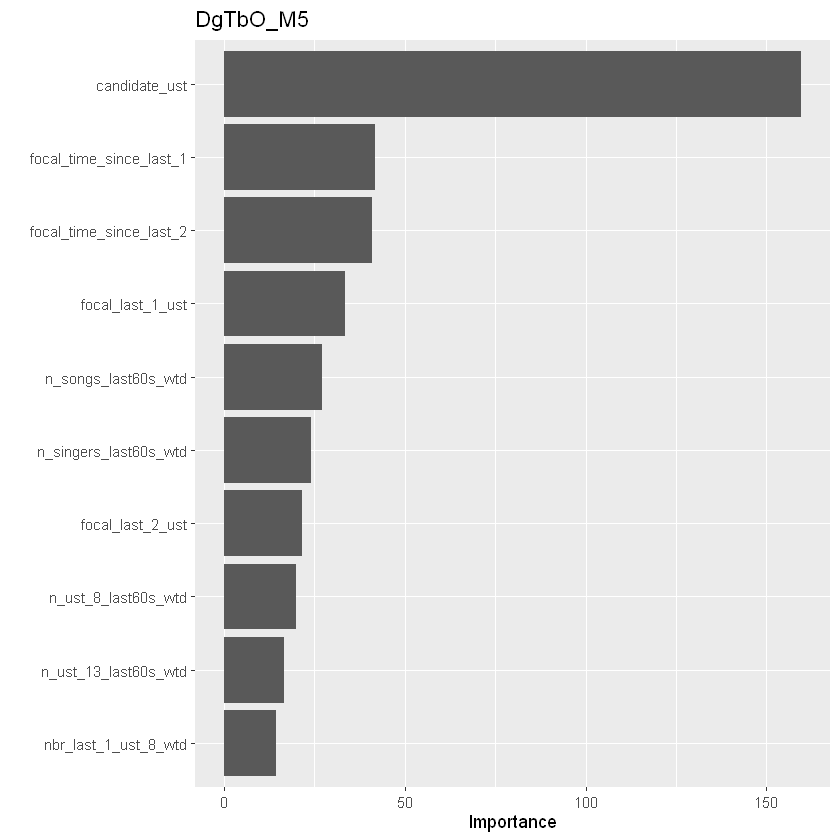

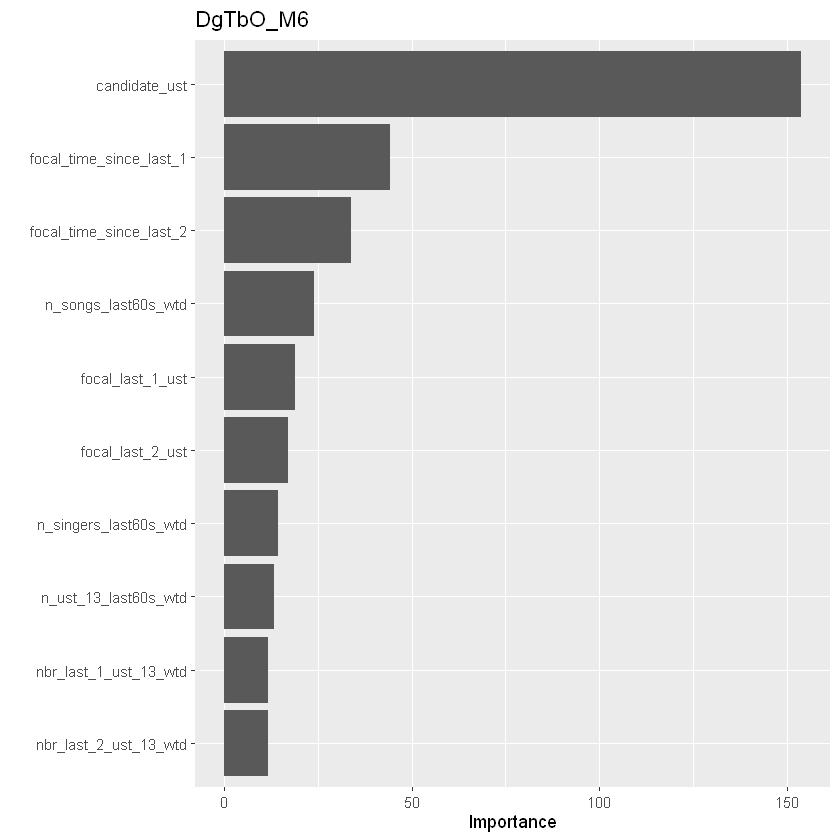

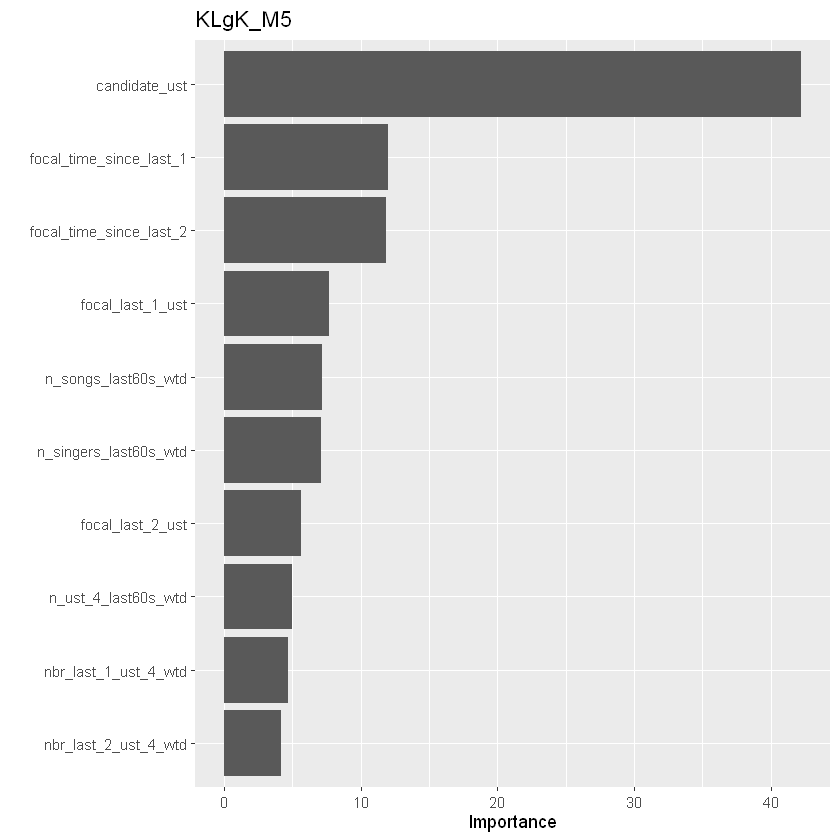

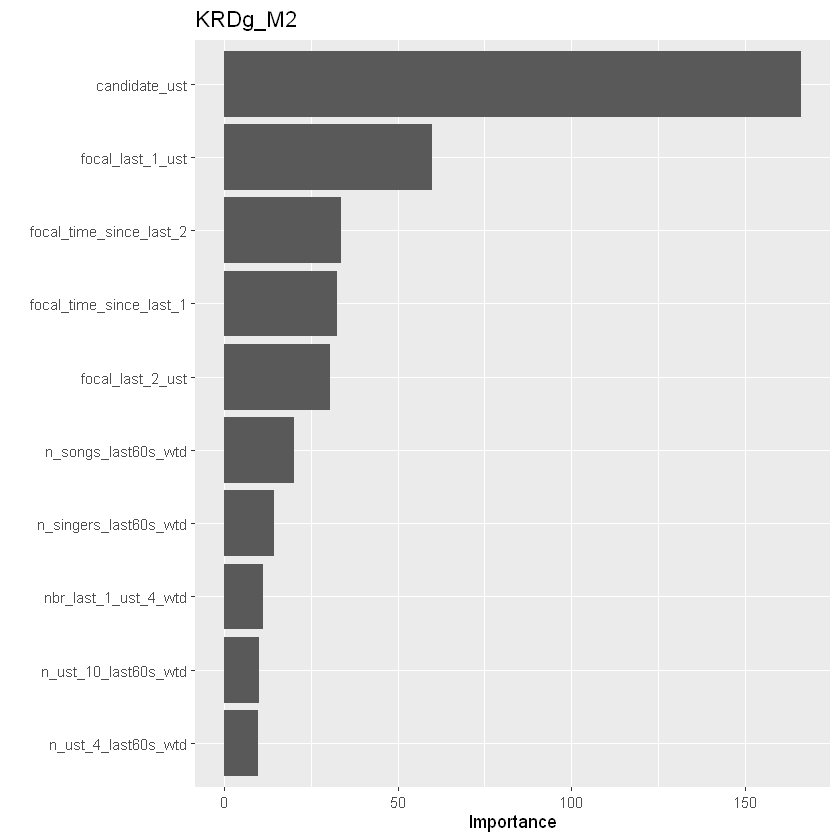

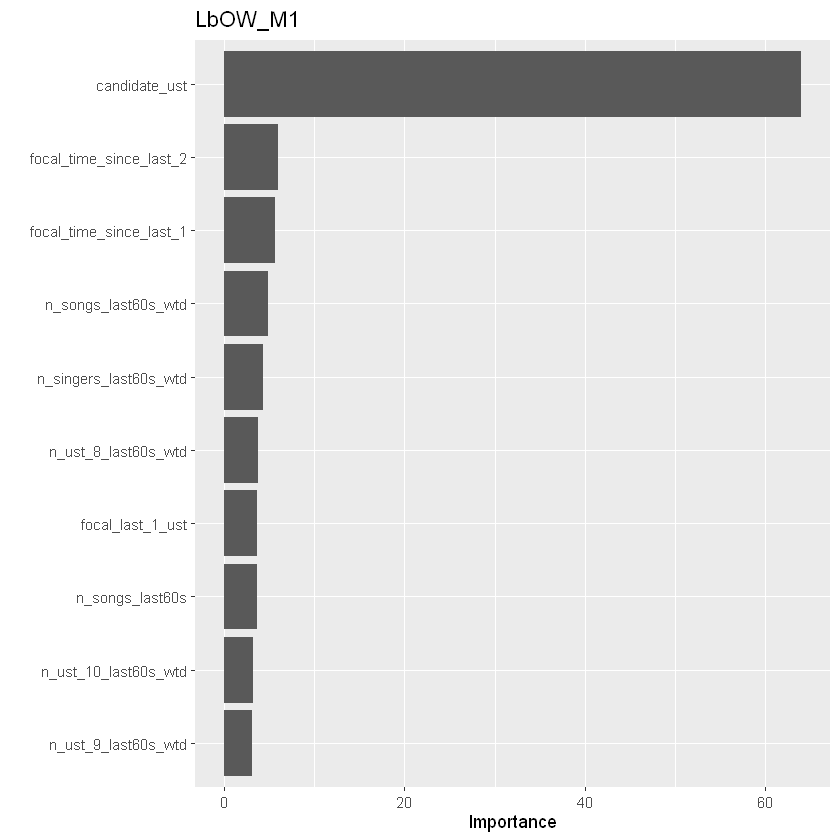

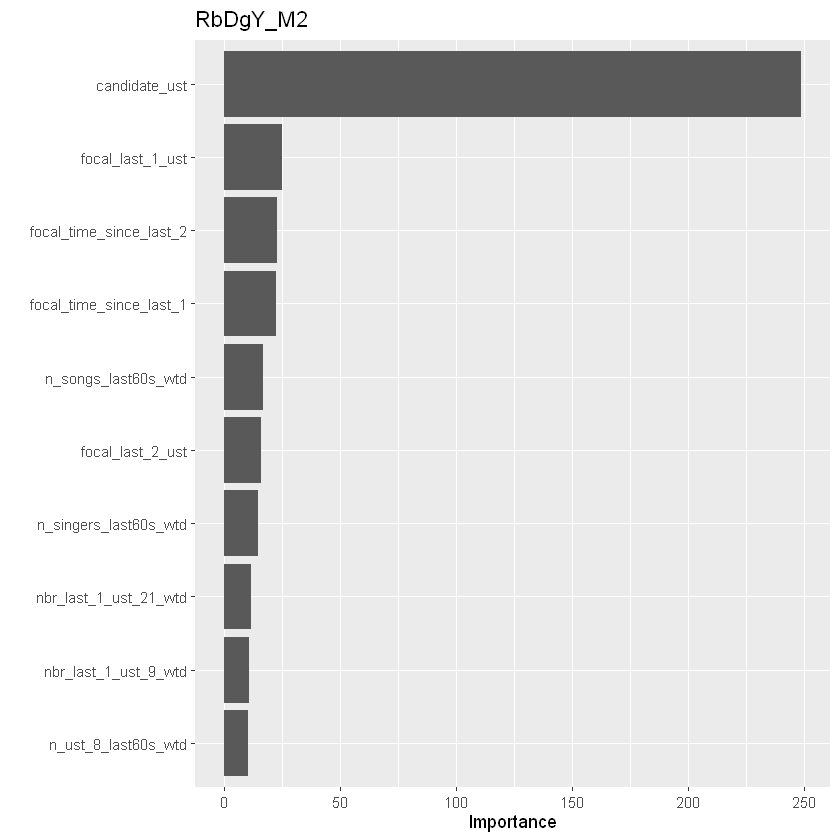

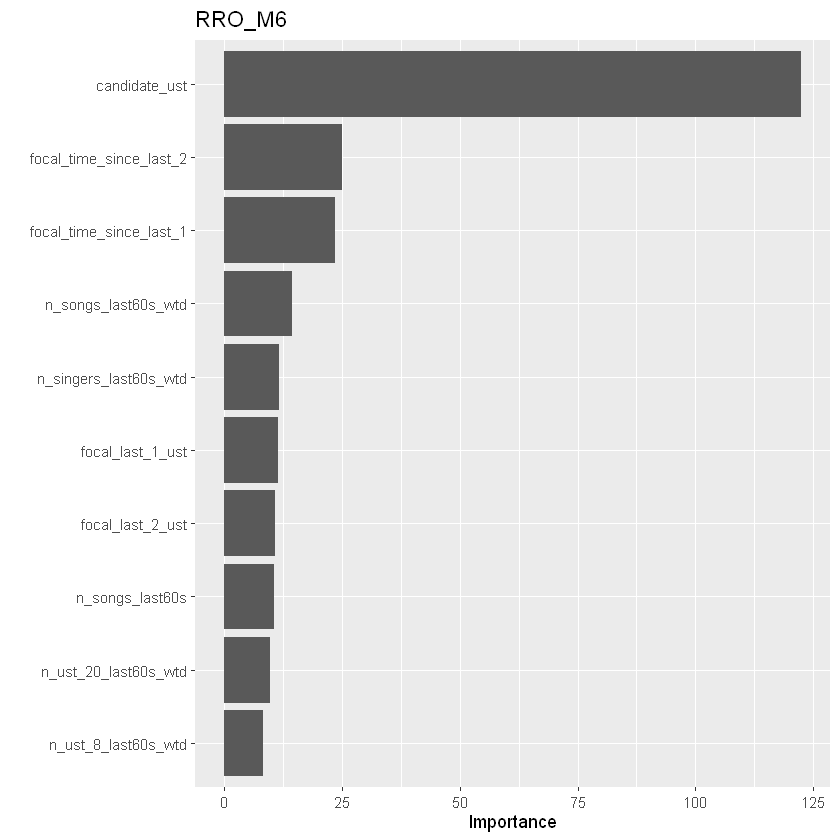

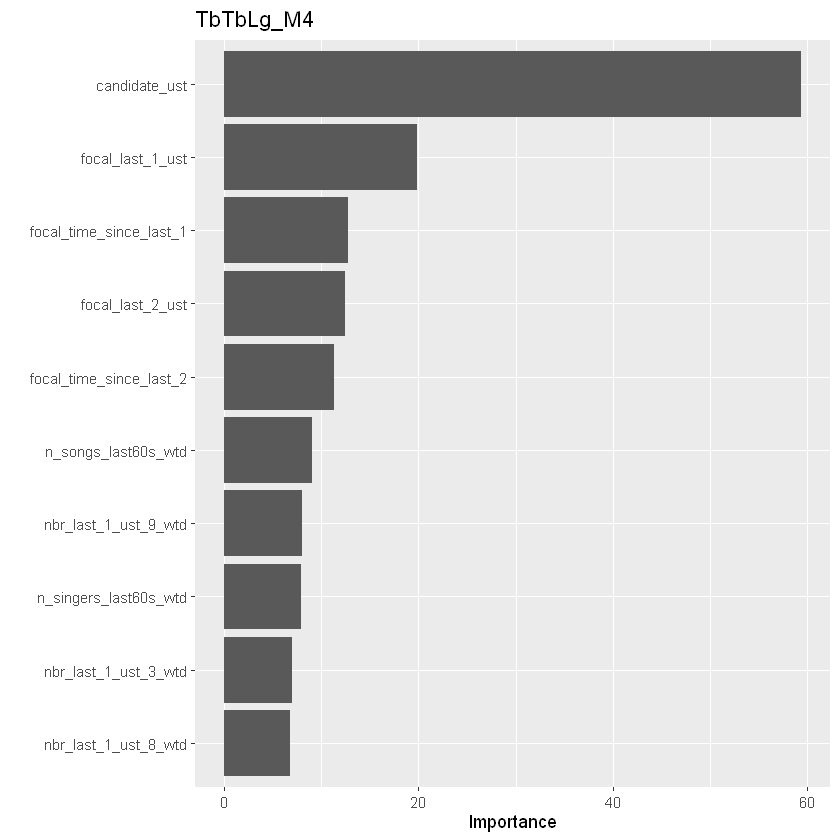

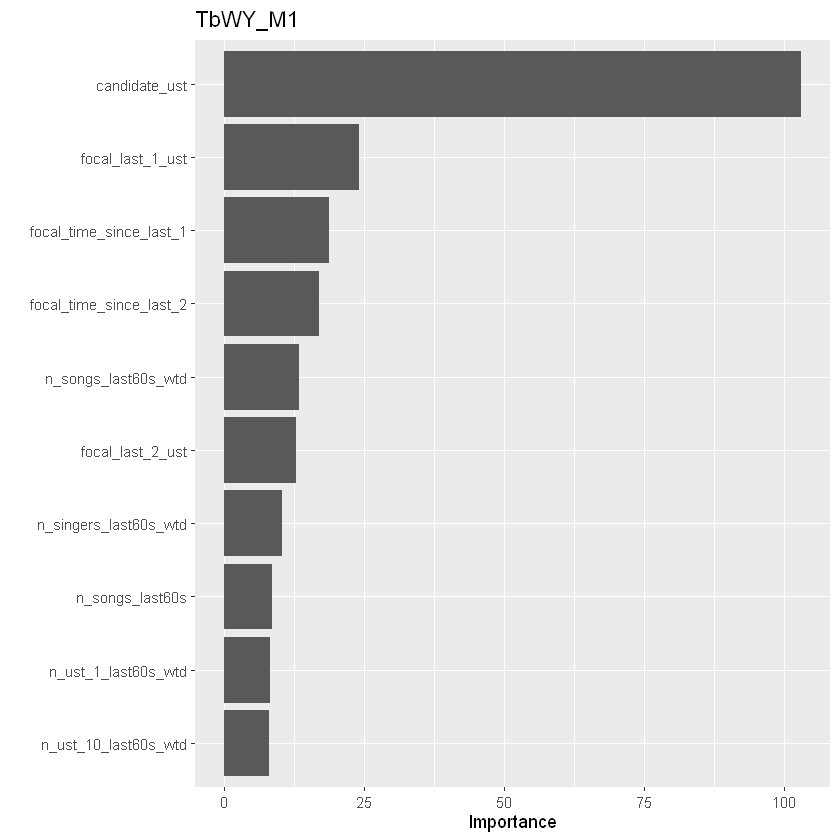

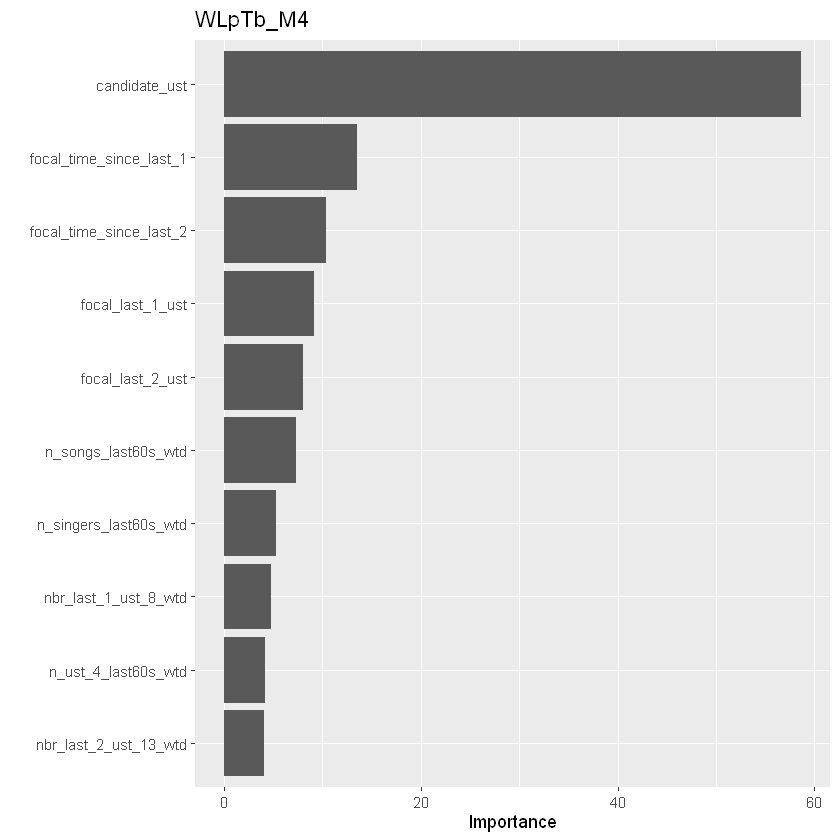

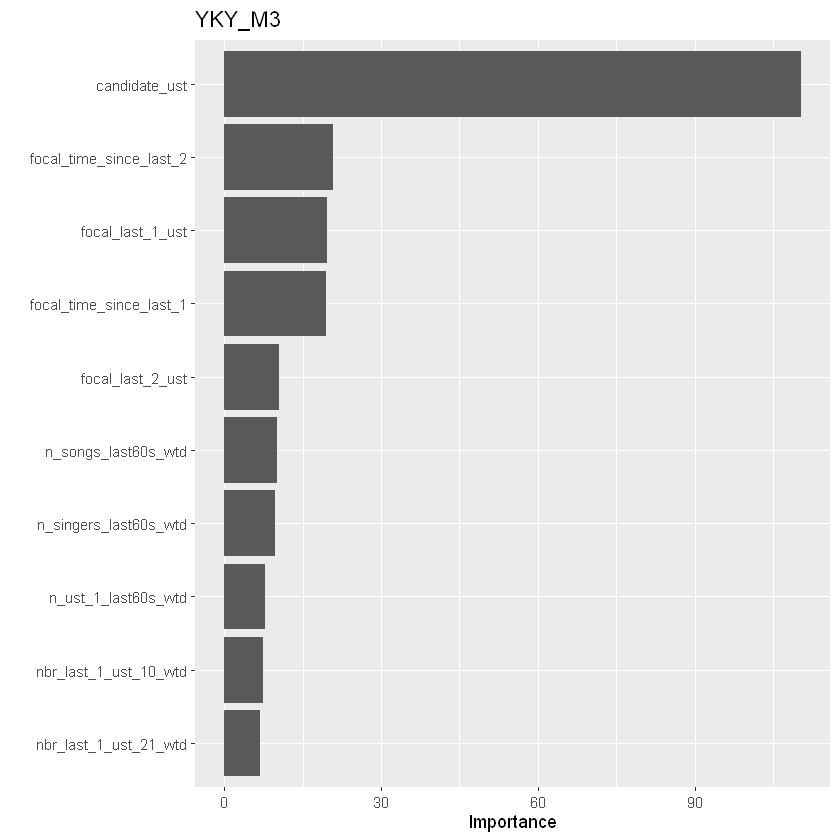

In [12]:
walk(male_results, ~ print(vip(.x$model %>% extract_fit_engine(), num_features = 10) + labs(title = .x$focal_male)))

Candidate-ranking metrics

In [ ]:
# ==============================================================================
# BASELINE MODEL: always predict the song type that was most common in training
#
# For each male:
#   1. Count how often each song type was the TRUE match in his training events.
#   2. Rank the song types by that count (ties: lower song type number first). The top type is the
#      prediction for EVERY event; the 2nd is the runner-up, and so on.
#   3. Score the test events: top-1 accuracy, top-3 recall, mean reciprocal rank and mean rank,
#      the same definitions as the forest's metrics.
#
# Only training events are used to pick the song type, so there is no leakage from the test data.
# Every event contains every song type in the male's repertoire as a candidate, so the baseline's
# ranking is the same for every event.
# ==============================================================================

baseline_one_male <- function(train, test, focal_male) {
    # How often each song type was the true match in the training events (all repertoire types listed)
    freq <- train %>%
        filter(match_class == "match") %>%
        count(candidate_ust = as.character(candidate_ust), name = "n_train") %>%
        right_join(tibble(candidate_ust = levels(train$candidate_ust)), by = "candidate_ust") %>%
        mutate(n_train = replace_na(n_train, 0L)) %>%
        arrange(desc(n_train), as.numeric(candidate_ust)) %>%
        mutate(baseline_rank = row_number())

    # Rank of each test event's true song type in that fixed ordering
    true_types <- test %>%
        filter(match_class == "match") %>%
        transmute(event_id, candidate_ust = as.character(candidate_ust)) %>%
        left_join(select(freq, candidate_ust, baseline_rank), by = "candidate_ust")

    tibble(focal_male = focal_male,
           n_test_events = nrow(true_types),
           baseline_song_type = freq$candidate_ust[1],
           baseline_share_of_training_events = freq$n_train[1] / sum(freq$n_train),
           baseline_accuracy = mean(true_types$baseline_rank == 1),
           baseline_top3_recall = mean(true_types$baseline_rank <= 3),
           baseline_mean_reciprocal_rank = mean(1 / true_types$baseline_rank),
           baseline_mean_rank = mean(true_types$baseline_rank))
}

baseline_metrics <- pmap_dfr(
    list(male_train_data, male_test_data, names(male_train_data)),
    baseline_one_male
)

cat("\nBASELINE MODEL: always predict the most common song type in the training events\n\n")
print(baseline_metrics, n = Inf, width = Inf)

# ---- Forest vs. baseline, per male ---------------------------------------------
# For every "_vs_baseline" column, positive = the forest is better than the baseline.
model_vs_baseline <- per_male_metrics %>%
    select(focal_male, random_baseline_accuracy, accuracy, top3_recall, mean_reciprocal_rank, mean_rank) %>%
    left_join(select(baseline_metrics, -n_test_events), by = "focal_male") %>%
    mutate(accuracy_vs_baseline  = accuracy - baseline_accuracy,
           top3_vs_baseline      = top3_recall - baseline_top3_recall,
           mrr_vs_baseline       = mean_reciprocal_rank - baseline_mean_reciprocal_rank,
           mean_rank_vs_baseline = baseline_mean_rank - mean_rank)   # lower mean rank is better

cat("\nFOREST vs. BASELINE, per male (positive difference = the forest is better)\n\n")
print(model_vs_baseline %>%
          select(focal_male, random_baseline_accuracy, baseline_song_type, baseline_accuracy, accuracy,
                 accuracy_vs_baseline, top3_recall, baseline_top3_recall, top3_vs_baseline),
      n = Inf, width = Inf)

cat("\nAVERAGE ACROSS MALES\n\n")
print(model_vs_baseline %>%
          summarise(random_accuracy       = mean(random_baseline_accuracy),
                    baseline_accuracy     = mean(baseline_accuracy),
                    forest_accuracy       = mean(accuracy),
                    mean_gain             = mean(accuracy_vs_baseline),
                    se_gain               = sd(accuracy_vs_baseline) / sqrt(n()),
                    n_males_forest_better = sum(accuracy_vs_baseline > 0),
                    n_males               = n(),
                    baseline_top3_recall  = mean(baseline_top3_recall),
                    forest_top3_recall    = mean(top3_recall),
                    baseline_mrr          = mean(baseline_mean_reciprocal_rank),
                    forest_mrr            = mean(mean_reciprocal_rank)),
      width = Inf)

# Save next to the other results
write_csv(baseline_metrics, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_baseline_metrics.csv")))



In [13]:
per_male_metrics %>% summarise(
    macro_accuracy = mean(accuracy),
    macro_random_baseline = mean(random_baseline_accuracy),
    macro_top3_recall = mean(top3_recall),
    macro_mean_reciprocal_rank = mean(mean_reciprocal_rank),
    macro_mean_rank = mean(mean_rank)
)

macro_accuracy,macro_random_baseline,macro_top3_recall,macro_mean_reciprocal_rank,macro_mean_rank
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.2444882,0.04653498,0.5085806,0.4307534,4.853922


Comparison with notebook 03 (if its results were saved)

The comparison is indicative only: the two runs use different feature sets, and when `DROP_NA_EVENTS` is TRUE they also use different event sets and therefore different train/test splits.

In [14]:
baseline_path <- file.path(RESULTS_DIR, "candidate_match_test_metrics.csv")
if (file.exists(baseline_path)) {
    nb03 <- read_csv(baseline_path, show_col_types = FALSE) %>%
        select(focal_male, accuracy_nb03 = accuracy, top3_recall_nb03 = top3_recall, mrr_nb03 = mean_reciprocal_rank)
    per_male_metrics %>%
        select(focal_male, n_test_events, accuracy, random_baseline_accuracy, top3_recall, mean_reciprocal_rank) %>%
        left_join(nb03, by = "focal_male") %>%
        mutate(accuracy_change = accuracy - accuracy_nb03)
} else {
    message("No notebook 03 results found at ", baseline_path)
}

focal_male,n_test_events,accuracy,random_baseline_accuracy,top3_recall,mean_reciprocal_rank,accuracy_nb03,top3_recall_nb03,mrr_nb03,accuracy_change
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,347,0.2478386,0.03571429,0.4726225,0.4329731,0.1514286,0.2742857,0.2702980,0.09641005
DgTbO_M6,297,0.1919192,0.03571429,0.4511785,0.3897750,0.1233333,0.2766667,0.2660056,0.06858586
KLgK_M5,152,0.1842105,0.05263158,0.4407895,0.3719164,0.1225806,0.3225806,0.2880223,0.06162988
KRDg_M2,303,0.3333333,0.03846154,0.5313531,0.4820352,0.1078431,0.2745098,0.2584806,0.22549020
LbOW_M1,207,0.1207729,0.05555556,0.4444444,0.3414772,0.1095238,0.3238095,0.2867574,0.01124914
RbDgY_M2,195,0.2974359,0.04761905,0.5897436,0.4905672,0.1522843,0.3756345,0.3312721,0.14515163
RRO_M6,158,0.2848101,0.05263158,0.5126582,0.4654639,0.1614907,0.3602484,0.3262272,0.12331944
TbTbLg_M4,217,0.2073733,0.05263158,0.4516129,0.3778106,0.1181818,0.2636364,0.2782545,0.08919145
TbWY_M1,178,0.3370787,0.05882353,0.7134831,0.5447282,0.2154696,0.4475138,0.3973848,0.12160904


Save results

In [15]:
# Save model results using the model name defined above.
dir.create(RESULTS_DIR, recursive = TRUE, showWarnings = FALSE)

per_male_metrics <- map_dfr(male_results, "metrics")
all_event_predictions <- map_dfr(male_results, ~ .x$event_predictions)
all_tuning_results <- map2_dfr(male_results, names(male_results), ~ .x$tuning_results %>% mutate(focal_male = .y))
all_features <- imap_dfr(model_data_by_male, ~ tibble(focal_male = .y, predictor = attr(.x, "predictor_cols")))

write_csv(per_male_metrics, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_test_metrics.csv")))
write_csv(all_event_predictions, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_event_predictions.csv")))
write_csv(all_tuning_results, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_tuning_results.csv")))
write_csv(all_features, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_features.csv")))
saveRDS(male_results, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_models.rds")))

walk(male_results, function(result) {
    importance_chart <- result$model %>%
        extract_fit_engine() %>%
        vip(num_features = 10) +
        labs(title = paste(result$focal_male, MODEL_NAME)) +
        theme_bw()
    ggsave(
        file.path(RESULTS_DIR, paste0(MODEL_NAME, "_", result$focal_male, "_importance.png")),
        plot = importance_chart,
        width = 8,
        height = 6,
        units = "in"
    )
})

per_male_metrics

focal_male,n_test_events,accuracy,random_baseline_accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,347,0.2478386,0.03571429,0.2399041,0.16110348,0.4726225,0.4329731,4.345821
DgTbO_M6,297,0.1919192,0.03571429,0.1426803,0.08741202,0.4511785,0.3897750,4.939394
KLgK_M5,152,0.1842105,0.05263158,0.1842412,0.16404983,0.4407895,0.3719164,5.532895
KRDg_M2,303,0.3333333,0.03846154,0.2820810,0.19906665,0.5313531,0.4820352,5.250825
LbOW_M1,207,0.1207729,0.05555556,0.3729373,0.07988166,0.4444444,0.3414772,4.695652
RbDgY_M2,195,0.2974359,0.04761905,0.2803521,0.18617429,0.5897436,0.4905672,4.251282
RRO_M6,158,0.2848101,0.05263158,0.2300252,0.15566138,0.5126582,0.4654639,4.240506
TbTbLg_M4,217,0.2073733,0.05263158,0.1663278,0.17325248,0.4516129,0.3778106,5.981567
TbWY_M1,178,0.3370787,0.05882353,0.2596272,0.20120664,0.7134831,0.5447282,3.370787


In [16]:
# ==============================================================================
# Ablation: do neighbour song counts help, and does distance weighting help?
#
# Paste into a new cell at the END of the distance-weighted notebook (it reuses
# model_data_by_male, male_train_data, male_test_data and male_vfolds, so every
# model below is tuned and tested on exactly the same events, split and CV folds).
#
# Predictors (nothing else is used):
#   baseline   : candidate_ust + focal male's last two song types
#   unweighted : baseline + n_ust_<t>_window       (neighbour song counts, last 60 s)
#   weighted   : baseline + n_ust_<t>_last60s_wtd  (distance-weighted song counts)
#   both       : baseline + both sets of counts
#
# Left out on purpose: n_songs_* / n_singers_*, nbr_last_*, time-since-last-song.
# ==============================================================================

# ---- Settings ----------------------------------------------------------------
# FALSE: the unweighted counts are numeric, like the weighted ones, so the comparison
#        is not confounded by factor vs numeric coding.
# TRUE : keep them as factors, as in the main model.
WINDOW_COUNTS_AS_FACTOR <- FALSE

abl_tune_trees  <- 300
abl_final_trees <- 1000
abl_mtry_fracs  <- c(0.05, 0.10, 0.25, 0.50)   # mtry as a fraction of the number of predictors
abl_min_n_grid  <- c(5, 10, 20, 40)

abl_id_cols <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")
own_cols    <- paste0("focal_last_", OWN_LAGS, "_ust")

# ---- Helpers -----------------------------------------------------------------
abl_feature_sets <- function(col_names) {
    unw <- str_subset(col_names, "^n_ust_[0-9]+_window$")
    wtd <- str_subset(col_names, "^n_ust_[0-9]+_last[0-9]+s_wtd$")
    if (length(unw) == 0 || length(wtd) == 0) {
        stop("Unweighted or distance-weighted song count columns not found.")
    }
    list(
        baseline   = c("candidate_ust", own_cols),
        unweighted = c("candidate_ust", unw, own_cols),
        weighted   = c("candidate_ust", wtd, own_cols),
        both       = c("candidate_ust", unw, wtd, own_cols)
    )
}

abl_prep_df <- function(df, cols) {
    df <- df %>% select(all_of(abl_id_cols), all_of(cols))
    if (!WINDOW_COUNTS_AS_FACTOR) {
        df <- df %>% mutate(across(matches("^n_ust_[0-9]+_window$"), ~ as.numeric(as.character(.x))))
    }
    df
}

# Same recipe as the main model
abl_recipe <- function(df) {
    recipe(match_class ~ ., data = df) %>%
        update_role(focal_male, focal_id, male_number, event_id, new_role = "id") %>%
        step_unknown(all_nominal_predictors()) %>%
        step_impute_median(all_numeric_predictors()) %>%
        step_zv(all_predictors())
}

abl_make_grid <- function(n_predictors) {
    tidyr::crossing(
        mtry  = unique(pmax(1L, as.integer(round(abl_mtry_fracs * n_predictors)))),
        min_n = abl_min_n_grid
    )
}

abl_spec <- function(mtry, min_n, trees, threads = 1) {
    rand_forest(mtry = mtry, trees = trees, min_n = min_n) %>%
        set_engine("ranger", importance = "none", probability = TRUE,
                   num.threads = threads, respect.unordered.factors = "order") %>%
        set_mode("classification")
}

abl_top1 <- function(predictions) {
    dt <- as.data.table(predictions)
    dt[dt[, .I[which.max(.pred_match)], by = event_id]$V1, mean(match_class == "match")]
}

abl_rank_metrics <- function(pred) {
    ranks <- pred %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        summarise(rank = which(match_class == "match")[1], n_cand = n(), .groups = "drop")
    tibble(n_test_events = nrow(ranks),
           accuracy = mean(ranks$rank == 1),
           random_baseline = mean(1 / ranks$n_cand),
           top3_recall = mean(ranks$rank <= 3),
           mean_reciprocal_rank = mean(1 / ranks$rank),
           mean_rank = mean(ranks$rank))
}

# ---- One male: tune + test every feature set --------------------------------
run_ablation_one <- function(train, test, folds_idx, focal_male, threads = 1) {
    setDTthreads(1)
    map_dfr(abl_feature_sets(names(train)), .id = "feature_set", function(cols) {
        tr <- abl_prep_df(train, cols)
        te <- abl_prep_df(test, cols)
        grid <- abl_make_grid(length(cols))

        # Prep + bake each CV fold once (same folds as the main model)
        folds <- map(folds_idx, function(idx) {
            a   <- tr[idx$analysis, ]
            s   <- tr[idx$assessment, ]
            rec <- prep(abl_recipe(a))
            list(train = bake(rec, new_data = NULL, all_predictors(), all_outcomes()),
                 test  = bake(rec, new_data = s,    all_predictors(), all_outcomes()),
                 meta  = s %>% select(event_id, match_class))
        })

        tuning <- pmap_dfr(grid, function(mtry, min_n) {
            acc <- map_dbl(folds, function(f) {
                spec  <- abl_spec(min(mtry, ncol(f$train) - 1L), min_n, abl_tune_trees, threads)
                fit_i <- fit(spec, match_class ~ ., data = f$train)
                preds <- predict(fit_i, f$test, type = "prob") %>% bind_cols(f$meta)
                abl_top1(preds)
            })
            tibble(mtry = mtry, min_n = min_n,
                   cv_accuracy = mean(acc), cv_se = sd(acc) / sqrt(length(acc)))
        }) %>% arrange(desc(cv_accuracy), cv_se)
        best <- tuning %>% slice(1)

        # Refit on all training data, evaluate on the held-out test events
        rec  <- prep(abl_recipe(tr))
        tr_b <- bake(rec, new_data = NULL, all_predictors(), all_outcomes())
        te_b <- bake(rec, new_data = te,   all_predictors(), all_outcomes())
        spec  <- abl_spec(min(best$mtry, ncol(tr_b) - 1L), best$min_n, abl_final_trees, threads)
        fit_f <- fit(spec, match_class ~ ., data = tr_b)
        pred  <- predict(fit_f, te_b, type = "prob") %>% bind_cols(te %>% select(event_id, match_class))

        bind_cols(tibble(focal_male = focal_male, n_predictors = length(cols)),
                  best %>% select(mtry, min_n, cv_accuracy),
                  abl_rank_metrics(pred))
    })
}

# ---- Run in parallel across males --------------------------------------------
# Row indices of each CV fold, so the folds can be re-applied to the column subsets
fold_idx <- map(male_vfolds, function(v) {
    map(v$splits, function(s) {
        list(analysis   = s$in_id,
             assessment = setdiff(seq_len(nrow(s$data)), s$in_id))
    })
})

plan(multisession, workers = max(1, parallel::detectCores() - 1))

ablation_results <- future_pmap_dfr(
    list(male_train_data, male_test_data, fold_idx, names(male_train_data)),
    run_ablation_one,
    threads = 1,
    .options = furrr_options(
        seed = TRUE,
        packages = c("tidymodels", "ranger", "data.table", "dplyr", "purrr", "tibble", "tidyr", "stringr"),
        globals = c("abl_id_cols", "own_cols", "abl_feature_sets", "abl_prep_df", "abl_recipe",
                    "abl_make_grid", "abl_spec", "abl_top1", "abl_rank_metrics",
                    "abl_tune_trees", "abl_final_trees", "abl_mtry_fracs", "abl_min_n_grid",
                    "WINDOW_COUNTS_AS_FACTOR")
    )
)

plan(sequential)

# ---- Results -----------------------------------------------------------------
feature_levels <- c("baseline", "unweighted", "weighted", "both")
ablation_results <- ablation_results %>%
    mutate(feature_set = factor(feature_set, levels = feature_levels))

write_csv(ablation_results, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_ablation.csv")))

# 1. Averages across males
ablation_summary <- ablation_results %>%
    group_by(feature_set) %>%
    summarise(mean_predictors = mean(n_predictors),
              accuracy = mean(accuracy),
              random_baseline = mean(random_baseline),
              top3_recall = mean(top3_recall),
              mean_reciprocal_rank = mean(mean_reciprocal_rank),
              mean_rank = mean(mean_rank),
              .groups = "drop")
print(ablation_summary)

# 2. Top-1 accuracy per male
acc_wide <- ablation_results %>%
    select(focal_male, feature_set, accuracy) %>%
    pivot_wider(names_from = feature_set, values_from = accuracy)
print(acc_wide, n = Inf)

# 3. Paired differences in top-1 accuracy (positive = the first model is better)
paired_differences <- acc_wide %>%
    transmute(focal_male,
              `unweighted - baseline` = unweighted - baseline,
              `weighted - baseline`   = weighted - baseline,
              `weighted - unweighted` = weighted - unweighted,
              `both - unweighted`     = both - unweighted,
              `both - weighted`       = both - weighted) %>%
    pivot_longer(-focal_male, names_to = "comparison", values_to = "diff") %>%
    mutate(comparison = factor(comparison, levels = unique(comparison))) %>%
    group_by(comparison) %>%
    summarise(mean_diff = mean(diff),
              se = sd(diff) / sqrt(n()),
              n_males_better = sum(diff > 0),
              n_males = n(),
              .groups = "drop")
print(paired_differences)

Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'tidymodels' was built under R version 4.5.3"
Warning message:
"package 'broom' was built under R version 4.5.3"
Warning message:
"package 'dials' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'infer' was built under R version 4.5.3"
Warning message:
"package 'modeldata' was built under R version 4.5.3"
Warning message:
"package 'parsnip' was built under R version 4.5.3"
Warning message:
"package 'recipes' was built under R version 4.5.3"
Warning message:
"package 'rsample' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'tune' was built under R version 4.5.3"
Warning message:
"package 'yardstick' was bui

# A tibble: 4 × 7
  feature_set mean_predictors accuracy random_baseline top3_recall
  <fct>                 <dbl>    <dbl>           <dbl>       <dbl>
1 baseline                3      0.269          0.0465       0.525
2 unweighted             72.4    0.249          0.0465       0.480
3 weighted               25.3    0.220          0.0465       0.466
4 both                   94.6    0.229          0.0465       0.474
# ℹ 2 more variables: mean_reciprocal_rank <dbl>, mean_rank <dbl>
# A tibble: 11 × 5
   focal_male baseline unweighted weighted  both
   <chr>         <dbl>      <dbl>    <dbl> <dbl>
 1 DgTbO_M5      0.254      0.256    0.242 0.245
 2 DgTbO_M6      0.189      0.175    0.165 0.141
 3 KLgK_M5       0.191      0.197    0.178 0.191
 4 KRDg_M2       0.366      0.343    0.317 0.343
 5 LbOW_M1       0.227      0.232    0.140 0.174
 6 RbDgY_M2      0.277      0.179    0.179 0.179
 7 RRO_M6        0.253      0.278    0.285 0.291
 8 TbTbLg_M4     0.226      0.203    0.152 0.152
 9 Tb

In [17]:
# ==============================================================================
# Ablation v2: candidate-aligned features
#
# Paste into a new cell at the END of the distance-weighted notebook. It reuses
# model_data_by_male, male_train_data, male_test_data and male_vfolds, so every model
# is tuned and tested on the same events, split and CV folds as the main model.
#
# The earlier per-song-type columns (n_ust_<t>_window, n_ust_<t>_last60s_wtd) have the same
# value on every candidate row of an event. The new features are aligned to the candidate:
# each is looked up for the candidate's own song type, so it differs between the candidates
# of one event and says directly "how much does the context favour THIS candidate?".
#
# Not included: "time since the candidate type was last sung by anyone". It needs raw
# timestamps, which are not in the model data (it would have to be built in notebook 02).
# ==============================================================================

# ---- Settings ----------------------------------------------------------------
# FALSE: the old per-type unweighted counts are numeric (like everything else here).
# TRUE : keep them as factors, as in the main model.
WINDOW_COUNTS_AS_FACTOR    <- FALSE
# Also fit the earlier per-song-type design as a reference, and combined with the new features.
INCLUDE_PER_TYPE_REFERENCE <- TRUE

abl_tune_trees  <- 300
abl_final_trees <- 1000
abl_mtry_fracs  <- c(0.05, 0.10, 0.25, 0.50)   # mtry as a fraction of the number of predictors
abl_min_n_grid  <- c(5, 10, 20, 40)

abl_id_cols <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")
own_cols    <- paste0("focal_last_", OWN_LAGS, "_ust")

# ---- Printing helpers ----------------------------------------------------------
cat_header <- function(txt) {
    cat("\n", strrep("=", 78), "\n", txt, "\n", strrep("=", 78), "\n", sep = "")
}

collapse_ranges <- function(x) {          # c(1,3,4,5,9) -> "1, 3-5, 9"
    x <- sort(unique(as.integer(x[!is.na(x)])))
    if (length(x) == 0) return("(none)")
    grp <- cumsum(c(1, diff(x) != 1))
    paste(tapply(x, grp, function(v) if (length(v) == 1) as.character(v) else paste0(min(v), "-", max(v))),
          collapse = ", ")
}

describe_cols <- function(cols) {
    if (length(cols) == 0) return("(none)")
    if (length(cols) <= 6) return(paste(cols, collapse = ", "))
    types <- str_extract(cols, "(?<=n_ust_)[0-9]+")
    sprintf("%d columns, one per song type (types %s)", length(cols), collapse_ranges(types))
}

group_desc <- c(
    candidate      = "candidate_ust: the song type being scored (factor).",
    own_history    = "focal_last_k_ust: the focal male's own previous k-th song types (factors).",
    own_repeat     = "cand_repeats_own_last_k: 1 if the candidate is the same song type as the focal male's k-th last song, else 0.",
    cand_count_unw = "cand_n_songs_unweighted: number of neighbour songs of the CANDIDATE's type in the window; every neighbour counts equally.",
    cand_count_wtd = "cand_n_songs_weighted: the same count, but each song is weighted by the singer's distance to the focal male (closer = heavier).",
    cand_last_wtd  = "cand_nbr_last_k_weighted: summed distance weights of the neighbours whose k-th most recent song is the CANDIDATE's type.",
    per_type_unw   = "n_ust_<t>_window: OLD design. Unweighted neighbour song counts per song type t; identical on every candidate row of an event.",
    per_type_wtd   = "n_ust_<t>_last60s_wtd: OLD design. Distance-weighted neighbour song counts per song type t; identical on every candidate row of an event."
)

# ---- Candidate-aligned feature builder -----------------------------------------
# For each row, picks the value of the per-type column that belongs to the row's candidate type.
abl_pick_by_candidate <- function(df, pattern, cand_chr) {
    cols <- str_subset(names(df), pattern)
    if (length(cols) == 0) stop("No columns match ", pattern)
    types <- str_match(cols, pattern)[, 2]
    mat   <- do.call(cbind, lapply(cols, function(cn) as.numeric(as.character(df[[cn]]))))
    j     <- match(cand_chr, types)
    ok    <- !is.na(j)
    out   <- numeric(nrow(df))                      # candidate types with no column -> 0
    out[ok] <- mat[cbind(which(ok), j[ok])]
    out
}

add_candidate_features <- function(df) {
    cand <- as.character(df$candidate_ust)

    for (k in OWN_LAGS) {
        own_k <- as.character(df[[paste0("focal_last_", k, "_ust")]])
        df[[paste0("cand_repeats_own_last_", k)]] <- as.numeric(!is.na(own_k) & own_k == cand)
    }

    df$cand_n_songs_unweighted <- abl_pick_by_candidate(df, "^n_ust_([0-9]+)_window$", cand)
    df$cand_n_songs_weighted   <- abl_pick_by_candidate(df, "^n_ust_([0-9]+)_last[0-9]+s_wtd$", cand)

    lags <- sort(unique(na.omit(as.integer(str_match(names(df), "^nbr_last_([0-9]+)_ust_[0-9]+_wtd$")[, 2]))))
    if (length(lags) == 0) stop("No nbr_last_<k>_ust_<t>_wtd columns found.")
    for (k in lags) {
        df[[paste0("cand_nbr_last_", k, "_weighted")]] <-
            abl_pick_by_candidate(df, paste0("^nbr_last_", k, "_ust_([0-9]+)_wtd$"), cand)
    }
    df
}

# Which columns belong to each feature group (resolved per male)
abl_groups <- function(col_names) {
    list(
        candidate      = "candidate_ust",
        own_history    = own_cols,
        own_repeat     = paste0("cand_repeats_own_last_", OWN_LAGS),
        cand_count_unw = "cand_n_songs_unweighted",
        cand_count_wtd = "cand_n_songs_weighted",
        cand_last_wtd  = str_subset(col_names, "^cand_nbr_last_[0-9]+_weighted$"),
        per_type_unw   = str_subset(col_names, "^n_ust_[0-9]+_window$"),
        per_type_wtd   = str_subset(col_names, "^n_ust_[0-9]+_last[0-9]+s_wtd$")
    )
}

# ---- Model definitions -----------------------------------------------------------
core <- c("candidate", "own_history", "own_repeat")
aligned_groups <- c(core, "cand_count_unw", "cand_count_wtd", "cand_last_wtd")

model_defs <- list(
    baseline = list(
        groups  = c("candidate", "own_history"),
        purpose = "Reference point: song-type base rates plus the focal male's own last two song types."),
    own_repeat = list(
        groups  = core,
        purpose = "Does flagging 'the candidate repeats my own recent song' explicitly help?"),
    cand_count_unw = list(
        groups  = c(core, "cand_count_unw"),
        purpose = "Does the unweighted count of neighbours singing the candidate's type help?"),
    cand_count_wtd = list(
        groups  = c(core, "cand_count_wtd"),
        purpose = "Same question, with distance weighting."),
    cand_count_both = list(
        groups  = c(core, "cand_count_unw", "cand_count_wtd"),
        purpose = "Both the unweighted and the distance-weighted candidate counts."),
    cand_last_wtd = list(
        groups  = c(core, "cand_last_wtd"),
        purpose = "Does matching the neighbours' most recent songs (distance-weighted) help?"),
    aligned_all = list(
        groups  = aligned_groups,
        purpose = "All candidate-aligned features together.")
)
if (INCLUDE_PER_TYPE_REFERENCE) {
    model_defs$per_type_both <- list(
        groups  = c("candidate", "own_history", "per_type_unw", "per_type_wtd"),
        purpose = "Reference: the earlier design (one column per song type, both weightings), no new features.")
    model_defs$aligned_plus_per_type <- list(
        groups  = c(aligned_groups, "per_type_unw", "per_type_wtd"),
        purpose = "New candidate-aligned features plus the earlier per-song-type columns.")
}

# ---- Step 1: build features, resolve columns --------------------------------------
cat_header("STEP 1: BUILDING CANDIDATE-ALIGNED FEATURES")
male_train_aug <- map(male_train_data, add_candidate_features)
male_test_aug  <- map(male_test_data,  add_candidate_features)

groups_by_male <- map(male_train_aug, ~ abl_groups(names(.x)))
model_cols_by_male <- map(groups_by_male, function(g) {
    map(model_defs, ~ unique(unlist(g[.x$groups], use.names = FALSE)))
})

# Every group a model asks for must be non-empty and present in the data
iwalk(groups_by_male, function(g, male) {
    used_groups <- unique(unlist(map(model_defs, "groups")))
    empty <- used_groups[map_int(g[used_groups], length) == 0]
    if (length(empty) > 0) stop(male, ": no columns found for group(s): ", paste(empty, collapse = ", "))
    missing_cols <- setdiff(unlist(model_cols_by_male[[male]]), names(male_train_aug[[male]]))
    if (length(missing_cols) > 0) stop(male, ": columns not in the data: ", paste(missing_cols, collapse = ", "))
})
cat("Built features for", length(male_train_aug), "males (train and test).\n")

# ---- Step 2: describe the feature groups and models --------------------------------
example_male <- names(groups_by_male)[1]

cat_header("STEP 2: FEATURE GROUPS (the building blocks)")
for (g in names(group_desc)) {
    cat(sprintf("\n  %-15s %s\n", g, group_desc[[g]]))
    cat(sprintf("  %-15s e.g. %s: %s\n", "", example_male, describe_cols(groups_by_male[[example_male]][[g]])))
}

cat_header(sprintf("STEP 3: MODELS TO FIT (%d models x %d males)", length(model_defs), length(male_train_aug)))
for (i in seq_along(model_defs)) {
    m  <- names(model_defs)[i]
    mc <- model_cols_by_male[[example_male]][[m]]
    n_by_male <- map_int(model_cols_by_male, ~ length(.x[[m]]))
    cat(sprintf("\n[%d] %s\n", i, m))
    cat("    Question   : ", model_defs[[m]]$purpose, "\n", sep = "")
    cat("    Built from : ", paste(model_defs[[m]]$groups, collapse = " + "), "\n", sep = "")
    cat("    Predictors : ", paste(sprintf("%s=%d", names(n_by_male), n_by_male), collapse = ", "), "\n", sep = "")
    if (length(mc) <= 12) {
        cat("    Columns (", example_male, "): ", paste(mc, collapse = ", "), "\n", sep = "")
    } else {
        cat("    Columns (", example_male, "): ", length(mc), " in total; the per-type groups are summarised above\n", sep = "")
        cat("      non-per-type columns: ", paste(setdiff(mc, c(groups_by_male[[example_male]]$per_type_unw,
                                                              groups_by_male[[example_male]]$per_type_wtd)), collapse = ", "),
            "\n", sep = "")
    }
}

# ---- Step 3: data checks ---------------------------------------------------------------
cat_header("STEP 4: DATA CHECKS BEFORE MODELLING")

cat("\nShare of training candidate rows whose song type has NO per-type column (these get a value of 0).\n")
cat("Anything above 0 means the per-type columns do not cover that male's repertoire.\n")
cover <- imap_dfr(male_train_aug, function(df, male) {
    cand  <- as.character(df$candidate_ust)
    types <- function(p) str_match(str_subset(names(df), p), p)[, 2]
    tibble(focal_male = male,
           unweighted_counts = mean(!(cand %in% types("^n_ust_([0-9]+)_window$"))),
           weighted_counts   = mean(!(cand %in% types("^n_ust_([0-9]+)_last[0-9]+s_wtd$"))))
})
print(cover, n = Inf)

cat("\nRaw signal: mean of each candidate-aligned feature on the TRUE match vs. the other candidates\n")
cat("(training data, pooled over males). An informative feature should be clearly higher on the true match.\n")
aligned_cols <- unique(unlist(map(groups_by_male, ~ unlist(.x[c("own_repeat", "cand_count_unw", "cand_count_wtd", "cand_last_wtd")]))))
signal <- map_dfr(male_train_aug, ~ select(.x, match_class, all_of(aligned_cols))) %>%
    pivot_longer(-match_class, names_to = "feature", values_to = "value") %>%
    group_by(feature, is_match = if_else(match_class == "match", "mean_on_true_match", "mean_on_others")) %>%
    summarise(mean = mean(value, na.rm = TRUE), .groups = "drop") %>%
    pivot_wider(names_from = is_match, values_from = mean) %>%
    mutate(ratio = mean_on_true_match / mean_on_others)
print(signal, n = Inf)

# ---- Fitting machinery (same procedure as the earlier ablation) -------------------------
abl_prep_df <- function(df, cols) {
    df <- df %>% select(all_of(abl_id_cols), all_of(cols))
    if (!WINDOW_COUNTS_AS_FACTOR) {
        df <- df %>% mutate(across(matches("^n_ust_[0-9]+_window$"), ~ as.numeric(as.character(.x))))
    }
    df
}

abl_recipe <- function(df) {
    recipe(match_class ~ ., data = df) %>%
        update_role(focal_male, focal_id, male_number, event_id, new_role = "id") %>%
        step_unknown(all_nominal_predictors()) %>%
        step_impute_median(all_numeric_predictors()) %>%
        step_zv(all_predictors())
}

abl_make_grid <- function(n_predictors) {
    tidyr::crossing(
        mtry  = unique(pmax(1L, as.integer(round(abl_mtry_fracs * n_predictors)))),
        min_n = abl_min_n_grid
    )
}

abl_spec <- function(mtry, min_n, trees, threads = 1) {
    rand_forest(mtry = mtry, trees = trees, min_n = min_n) %>%
        set_engine("ranger", importance = "none", probability = TRUE,
                   num.threads = threads, respect.unordered.factors = "order") %>%
        set_mode("classification")
}

abl_top1 <- function(predictions) {
    dt <- as.data.table(predictions)
    dt[dt[, .I[which.max(.pred_match)], by = event_id]$V1, mean(match_class == "match")]
}

abl_rank_metrics <- function(pred) {
    ranks <- pred %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        summarise(rank = which(match_class == "match")[1], n_cand = n(), .groups = "drop")
    tibble(n_test_events = nrow(ranks),
           accuracy = mean(ranks$rank == 1),
           random_baseline = mean(1 / ranks$n_cand),
           top3_recall = mean(ranks$rank <= 3),
           mean_reciprocal_rank = mean(1 / ranks$rank),
           mean_rank = mean(ranks$rank))
}

# One male: tune + test every model. model_cols is a named list: model name -> predictor columns.
run_ablation_one <- function(train, test, folds_idx, model_cols, focal_male, threads = 1) {
    setDTthreads(1)
    map_dfr(model_cols, .id = "model", function(cols) {
        tr   <- abl_prep_df(train, cols)
        te   <- abl_prep_df(test, cols)
        grid <- abl_make_grid(length(cols))

        folds <- map(folds_idx, function(idx) {       # prep + bake each CV fold once
            a   <- tr[idx$analysis, ]
            s   <- tr[idx$assessment, ]
            rec <- prep(abl_recipe(a))
            list(train = bake(rec, new_data = NULL, all_predictors(), all_outcomes()),
                 test  = bake(rec, new_data = s,    all_predictors(), all_outcomes()),
                 meta  = s %>% select(event_id, match_class))
        })

        tuning <- pmap_dfr(grid, function(mtry, min_n) {
            acc <- map_dbl(folds, function(f) {
                spec  <- abl_spec(min(mtry, ncol(f$train) - 1L), min_n, abl_tune_trees, threads)
                fit_i <- fit(spec, match_class ~ ., data = f$train)
                preds <- predict(fit_i, f$test, type = "prob") %>% bind_cols(f$meta)
                abl_top1(preds)
            })
            tibble(mtry = mtry, min_n = min_n,
                   cv_accuracy = mean(acc), cv_se = sd(acc) / sqrt(length(acc)))
        }) %>% arrange(desc(cv_accuracy), cv_se)
        best <- tuning %>% slice(1)

        rec  <- prep(abl_recipe(tr))                  # refit on all training data, test on held-out events
        tr_b <- bake(rec, new_data = NULL, all_predictors(), all_outcomes())
        te_b <- bake(rec, new_data = te,   all_predictors(), all_outcomes())
        spec  <- abl_spec(min(best$mtry, ncol(tr_b) - 1L), best$min_n, abl_final_trees, threads)
        fit_f <- fit(spec, match_class ~ ., data = tr_b)
        pred  <- predict(fit_f, te_b, type = "prob") %>% bind_cols(te %>% select(event_id, match_class))

        bind_cols(tibble(focal_male = focal_male, n_predictors = length(cols),
                         predictors_used = list(setdiff(names(tr_b), "match_class"))),
                  best %>% select(mtry, min_n, cv_accuracy),
                  abl_rank_metrics(pred))
    })
}

# ---- Run in parallel across males -------------------------------------------------------
# Row indices of each CV fold, so the main model's folds can be re-applied to the column subsets
fold_idx <- map(male_vfolds, function(v) {
    map(v$splits, function(s) {
        list(analysis   = s$in_id,
             assessment = setdiff(seq_len(nrow(s$data)), s$in_id))
    })
})

cat_header("STEP 5: FITTING")
cat(sprintf("Tuning and testing %d models for each of %d males (%d trees while tuning, %d for the final fit)...\n",
            length(model_defs), length(male_train_aug), abl_tune_trees, abl_final_trees))

plan(multisession, workers = max(1, parallel::detectCores() - 1))

ablation_results <- future_pmap_dfr(
    list(male_train_aug, male_test_aug, fold_idx, model_cols_by_male, names(male_train_aug)),
    run_ablation_one,
    threads = 1,
    .options = furrr_options(
        seed = TRUE,
        packages = c("tidymodels", "ranger", "data.table", "dplyr", "purrr", "tibble", "tidyr", "stringr"),
        globals = c("abl_id_cols", "abl_prep_df", "abl_recipe", "abl_make_grid", "abl_spec", "abl_top1",
                    "abl_rank_metrics", "abl_tune_trees", "abl_final_trees", "abl_mtry_fracs",
                    "abl_min_n_grid", "WINDOW_COUNTS_AS_FACTOR")
    )
)

plan(sequential)
cat("Done.\n")

# ---- Results ------------------------------------------------------------------------------
ablation_results <- ablation_results %>% mutate(model = factor(model, levels = names(model_defs)))

# Predictors the recipe actually passed to the forest (step_zv drops constant columns)
ablation_results$n_used  <- lengths(ablation_results$predictors_used)
ablation_results$dropped <- pmap(list(as.character(ablation_results$model), ablation_results$focal_male,
                                      ablation_results$predictors_used),
                                 function(m, male, used) setdiff(model_cols_by_male[[male]][[m]], used))

write_csv(ablation_results %>% select(-predictors_used, -dropped),
          file.path(RESULTS_DIR, paste0(MODEL_NAME, "_ablation_candidate_features.csv")))
write_csv(ablation_results %>% select(focal_male, model, predictors_used) %>% unnest(predictors_used),
          file.path(RESULTS_DIR, paste0(MODEL_NAME, "_ablation_candidate_features_predictors_used.csv")))

cat_header("RESULTS 1: PREDICTORS ACTUALLY USED BY EACH FOREST (after the recipe)")
cat("Predictors offered vs. used, averaged over males (the difference is columns dropped for having no variation):\n")
print(ablation_results %>% group_by(model) %>%
          summarise(mean_offered = mean(n_predictors), mean_used = mean(n_used), .groups = "drop"), n = Inf)
dropped_rows <- ablation_results %>% filter(lengths(dropped) > 0)
if (nrow(dropped_rows) == 0) {
    cat("No predictor was dropped by step_zv in any model.\n")
} else {
    cat("\nColumns dropped by step_zv:\n")
    pwalk(dropped_rows[c("focal_male", "model", "dropped")], function(focal_male, model, dropped) {
        cat(sprintf("  [%s] %s: %s\n", focal_male, model, describe_cols(dropped)))
    })
}

cat_header("RESULTS 2: AVERAGE ACROSS MALES")
ablation_summary <- ablation_results %>%
    group_by(model) %>%
    summarise(mean_predictors = mean(n_used),
              accuracy = mean(accuracy),
              random_baseline = mean(random_baseline),
              top3_recall = mean(top3_recall),
              mean_reciprocal_rank = mean(mean_reciprocal_rank),
              mean_rank = mean(mean_rank),
              .groups = "drop")
print(ablation_summary, n = Inf, width = Inf)

cat_header("RESULTS 3: TOP-1 ACCURACY PER MALE")
acc_wide <- ablation_results %>%
    select(focal_male, model, accuracy) %>%
    pivot_wider(names_from = model, values_from = accuracy)
print(acc_wide, n = Inf, width = Inf)

cat_header("RESULTS 4: PAIRED DIFFERENCES IN TOP-1 ACCURACY (first model minus second)")
cat("Positive = the first model is better. se is across males; n_males_better is how many males improved.\n")
comparisons <- list(
    c("own_repeat", "baseline"),
    c("cand_count_unw", "own_repeat"),
    c("cand_count_wtd", "own_repeat"),
    c("cand_count_wtd", "cand_count_unw"),
    c("cand_count_both", "cand_count_wtd"),
    c("cand_last_wtd", "own_repeat"),
    c("aligned_all", "own_repeat"),
    c("aligned_all", "baseline"),
    c("aligned_all", "per_type_both"),
    c("aligned_plus_per_type", "aligned_all")
)
comparisons <- keep(comparisons, ~ all(.x %in% names(acc_wide)))
paired_differences <- map_dfr(comparisons, function(cmp) {
    d <- acc_wide[[cmp[1]]] - acc_wide[[cmp[2]]]
    tibble(comparison = paste(cmp[1], "-", cmp[2]),
           mean_diff = mean(d), se = sd(d) / sqrt(length(d)),
           n_males_better = sum(d > 0), n_males = length(d))
})
print(paired_differences, n = Inf, width = Inf)


STEP 1: BUILDING CANDIDATE-ALIGNED FEATURES
Built features for 11 males (train and test).

STEP 2: FEATURE GROUPS (the building blocks)

  candidate       candidate_ust: the song type being scored (factor).
                  e.g. DgTbO_M5: candidate_ust

  own_history     focal_last_k_ust: the focal male's own previous k-th song types (factors).
                  e.g. DgTbO_M5: focal_last_1_ust, focal_last_2_ust

  own_repeat      cand_repeats_own_last_k: 1 if the candidate is the same song type as the focal male's k-th last song, else 0.
                  e.g. DgTbO_M5: cand_repeats_own_last_1, cand_repeats_own_last_2

  cand_count_unw  cand_n_songs_unweighted: number of neighbour songs of the CANDIDATE's type in the window; every neighbour counts equally.
                  e.g. DgTbO_M5: cand_n_songs_unweighted

  cand_count_wtd  cand_n_songs_weighted: the same count, but each song is weighted by the singer's distance to the focal male (closer = heavier).
                  e.g. DgTb

Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'tidymodels' was built under R version 4.5.3"
Warning message:
"package 'broom' was built under R version 4.5.3"
Warning message:
"package 'dials' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'infer' was built under R version 4.5.3"
Warning message:
"package 'modeldata' was built under R version 4.5.3"
Warning message:
"package 'parsnip' was built under R version 4.5.3"
Warning message:
"package 'recipes' was built under R version 4.5.3"
Warning message:
"package 'rsample' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'tune' was built under R version 4.5.3"
Warning message:
"package 'yardstick' was bui

Done.

RESULTS 1: PREDICTORS ACTUALLY USED BY EACH FOREST (after the recipe)
Predictors offered vs. used, averaged over males (the difference is columns dropped for having no variation):
# A tibble: 9 × 3
  model                 mean_offered mean_used
  <fct>                        <dbl>     <dbl>
1 baseline                       3         3  
2 own_repeat                     5         5  
3 cand_count_unw                 6         6  
4 cand_count_wtd                 6         6  
5 cand_count_both                7         7  
6 cand_last_wtd                  7         7  
7 aligned_all                    9         9  
8 per_type_both                 94.6      30.1
9 aligned_plus_per_type        101.       36.1

Columns dropped by step_zv:
  [DgTbO_M5] per_type_both: 109 columns, one per song type (types 3-4, 7, 9, 11, 14, 16-19, 21-29, 31-33, 35-36, 55-64, 83-98, 100-120, 153-172)
  [DgTbO_M5] aligned_plus_per_type: 109 columns, one per song type (types 3-4, 7, 9, 11, 14, 16-19, 21-2

In [ ]:

# ==============================================================================
# Add the baseline to the ablation tables (no need to re-run the ablations)
#
# Run this in the same session as the ablation, after `ablation_results` exists. The ablation's
# earlier model called "baseline" (candidate song type + the focal male's last two song types) is
# renamed "own_history", so that "baseline" now means the most-common-song-type model everywhere.
# ==============================================================================
if (exists("ablation_results")) {
    baseline_rows <- baseline_metrics %>%
        transmute(model = "baseline", focal_male, n_predictors = 0L, n_test_events,
                  accuracy = baseline_accuracy,
                  top3_recall = baseline_top3_recall,
                  mean_reciprocal_rank = baseline_mean_reciprocal_rank,
                  mean_rank = baseline_mean_rank)

    ablation_results <- ablation_results %>%
        mutate(model = recode(as.character(model), baseline = "own_history")) %>%
        bind_rows(baseline_rows) %>%
        mutate(model = fct_relevel(factor(model), "baseline"))

    cat("\nABLATION, average across males (baseline = most common song type)\n\n")
    print(ablation_results %>%
              group_by(model) %>%
              summarise(accuracy = mean(accuracy), top3_recall = mean(top3_recall),
                        mean_reciprocal_rank = mean(mean_reciprocal_rank), mean_rank = mean(mean_rank),
                        .groups = "drop"),
          n = Inf, width = Inf)
}